In [16]:
import sys
import torch
import pytorch_grad_cam

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("Grad-CAM: correctly installed")

Python: c:\Users\Usuario\AppData\Local\Python\pythoncore-3.14-64\python.exe
PyTorch: 2.15.0+cpu
Grad-CAM: correctly installed


# Explainability Analysis – Grad-CAM

## PART 1: Setup and Data Preparation

This section contains the libraries, model configuration, dataset preparation and preprocessing steps required to perform the explainability analysis.

## PART 2: First Grad-CAM Experiment: FULL Model – Fold 0

This section presents the first individual Grad-CAM visualization using the trained FULL model (fold 0) and one test ultrasound image.

In [17]:
from pathlib import Path

project_folder = Path.cwd()

print("Searching in:", project_folder)
print("\nFound model files (.pth):\n")

for file in project_folder.rglob("*.pth"):
    print(file)

Searching in: c:\Users\Usuario\Documents\UNI 4\PROYECTO EN CD\Project-data-science\notebooks

Found model files (.pth):



In [19]:
from pathlib import Path
import torch

# Define the project root directory (parent folder of the notebook directory).
PROJECT_ROOT = Path.cwd().parent

# Build the path to the FULL fold 0 checkpoint using a relative project path.
model_path = (
    PROJECT_ROOT
    / "efficientnet_models"
    / "best_efficientnet_full_fold0.pth"
)

# Check that the checkpoint exists before loading it.
print("Checkpoint exists:", model_path.exists())

# Load the model weights.
checkpoint = torch.load(
    model_path,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint loaded successfully")
print("Number of parameter entries:", len(checkpoint))

Checkpoint exists: True
Checkpoint loaded successfully
Number of parameter entries: 360


In [20]:
print("Last parameter names:")

for key in list(checkpoint.keys())[-10:]:
    print(key)

Last parameter names:
blocks.6.0.bn3.running_var
blocks.6.0.bn3.num_batches_tracked
conv_head.weight
bn2.weight
bn2.bias
bn2.running_mean
bn2.running_var
bn2.num_batches_tracked
classifier.1.weight
classifier.1.bias


In [22]:
%pip install timm

  Using cached timm-1.0.30-py3-none-any.whl.metadata (33 kB)
  Using cached pyyaml-6.0.3-cp314-cp314-win_amd64.whl.metadata (2.4 kB)
  Using cached huggingface_hub-2.4.0-py3-none-any.whl.metadata (16 kB)
  Using cached safetensors-0.8.0-cp310-abi3-win_amd64.whl.metadata (4.2 kB)
  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached hf_xet-1.8.0-cp38-abi3-win_amd64.whl.metadata (4.9 kB)
  Using cached httpx2-2.16.0-py3-none-any.whl.metadata (10 kB)
  Using cached anyio-4.15.1-py3-none-any.whl.metadata (4.7 kB)
  Using cached httpcore2-2.16.0-py3-none-any.whl.metadata (27 kB)
  Using cached truststore-0.10.5-py3-none-any.whl.metadata (4.5 kB)
  Using cached h11-0.16.0-py3-none-any.whl.metadata (8.3 kB)
Using cached timm-1.0.30-py3-none-any.whl (2.7 MB)
Using cached huggingface_hub-2.4.0-py3-none-any.whl (857 kB)
Using cached click-8.5.0-py3-none-any.whl (125 kB)
Using cached hf_xet-1.8.0-cp38-abi3-win_amd64.whl (3.9 MB)
Using cached httpx2-2.16.0-py3-none-any.whl (

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [23]:
import torch
import torch.nn as nn
import timm

def build_efficientnet_model(num_classes=2):
    model = timm.create_model(
        "efficientnet_b0",
        pretrained=False,
        in_chans=3
    )

    in_features = model.classifier.in_features

    model.classifier = nn.Sequential(
        nn.Dropout(p=0.4),
        nn.Linear(in_features, num_classes)
    )

    return model


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = build_efficientnet_model(num_classes=2).to(device)

model.load_state_dict(checkpoint)
model.eval()

print("FULL fold 0 model loaded successfully")
print("Device:", device)

c:\Users\Usuario\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


FULL fold 0 model loaded successfully
Device: cpu


In [ ]:
from pathlib import Path

images_folder = Path(
    r"C:\Users\Usuario\Documents\UNI 4\PROYECTO EN CD\DIRECTO FERNANDO\bbdd_kidney\images"
)

print("Folder exists:", images_folder.exists())

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

image_files = [
    file for file in images_folder.rglob("*")
    if file.suffix.lower() in image_extensions
]

print("Number of images:", len(image_files))
print("\nFirst 10 images:")

for file in image_files[:10]:
    print(file)

Folder exists: True
Number of images: 1985

First 10 images:
C:\Users\Usuario\Documents\UNI 4\PROYECTO EN CD\DIRECTO FERNANDO\bbdd_kidney\images\1.jpg
C:\Users\Usuario\Documents\UNI 4\PROYECTO EN CD\DIRECTO FERNANDO\bbdd_kidney\images\10.jpg
C:\Users\Usuario\Documents\UNI 4\PROYECTO EN CD\DIRECTO FERNANDO\bbdd_kidney\images\100.jpg
C:\Users\Usuario\Documents\UNI 4\PROYECTO EN CD\DIRECTO FERNANDO\bbdd_kidney\images\1000.jpg
C:\Users\Usuario\Documents\UNI 4\PROYECTO EN CD\DIRECTO FERNANDO\bbdd_kidney\images\1001.jpg
C:\Users\Usuario\Documents\UNI 4\PROYECTO EN CD\DIRECTO FERNANDO\bbdd_kidney\images\1002.jpg
C:\Users\Usuario\Documents\UNI 4\PROYECTO EN CD\DIRECTO FERNANDO\bbdd_kidney\images\1003.jpg
C:\Users\Usuario\Documents\UNI 4\PROYECTO EN CD\DIRECTO FERNANDO\bbdd_kidney\images\1004.jpg
C:\Users\Usuario\Documents\UNI 4\PROYECTO EN CD\DIRECTO FERNANDO\bbdd_kidney\images\1005.jpg
C:\Users\Usuario\Documents\UNI 4\PROYECTO EN CD\DIRECTO FERNANDO\bbdd_kidney\images\1006.jpg


In [26]:
labels_folder = images_folder.parent / "labels"

print("Labels folder exists:", labels_folder.exists())
print("\nFiles inside labels folder:")

for file in labels_folder.iterdir():
    print(file.name)

Labels folder exists: True

Files inside labels folder:
1.txt
10.txt
100.txt
1000.txt
1001.txt
1002.txt
1003.txt
1004.txt
1005.txt
1006.txt
1007.txt
1008.txt
1009.txt
101.txt
1010.txt
1011.txt
1012.txt
1013.txt
1014.txt
1015.txt
1016.txt
1017.txt
1018.txt
1019.txt
102.txt
1020.txt
1021.txt
1022.txt
1023.txt
1024.txt
1025.txt
1026.txt
1027.txt
1028.txt
1029.txt
103.txt
1030.txt
1031.txt
1032.txt
1033.txt
1034.txt
1035.txt
1036.txt
1037.txt
1038.txt
1039.txt
104.txt
1040.txt
1041.txt
1042.txt
1043.txt
1044.txt
1045.txt
1046.txt
1047.txt
1048.txt
1049.txt
105.txt
1050.txt
1051.txt
1052.txt
1053.txt
1054.txt
1055.txt
1056.txt
1057.txt
1058.txt
1059.txt
106.txt
1060.txt
1061.txt
1062.txt
1063.txt
1064.txt
1065.txt
1066.txt
1067.txt
1068.txt
1069.txt
107.txt
1070.txt
1071.txt
1072.txt
1073.txt
1074.txt
1075.txt
1076.txt
1077.txt
1078.txt
1079.txt
108.txt
1080.txt
1081.txt
1082.txt
1083.txt
1084.txt
1085.txt
1086.txt
1087.txt
1088.txt
1089.txt
109.txt
1090.txt
1091.txt
1092.txt
1093.txt
1094.

In [27]:
label_file = labels_folder / "1.txt"

print("Label file:", label_file)
print("Label content:")

print(label_file.read_text())

Label file: C:\Users\Usuario\Documents\UNI 4\PROYECTO EN CD\DIRECTO FERNANDO\bbdd_kidney\labels\1.txt
Label content:
Image filename: 1.jpg
Global diagnosis: 1
Global pathologies: 0 0
View: 0
Bounding box 1: 326 196 48 32 5



In [28]:
for image_id in ["1", "10", "100", "1000"]:
    label_file = labels_folder / f"{image_id}.txt"

    print(f"\n--- {image_id}.txt ---")
    print(label_file.read_text())


--- 1.txt ---
Image filename: 1.jpg
Global diagnosis: 1
Global pathologies: 0 0
View: 0
Bounding box 1: 326 196 48 32 5


--- 10.txt ---
Image filename: 10.jpg
Global diagnosis: 1
Global pathologies: 1 0
View: 0


--- 100.txt ---
Image filename: 100.jpg
Global diagnosis: 1
Global pathologies: 0 0
View: 0
Bounding box 1: 325 180 35 72 1
Bounding box 2: 224 220 46 115 8


--- 1000.txt ---
Image filename: 1000.jpg
Global diagnosis: 1
Global pathologies: 0 0
View: 0
Bounding box 1: 375 168 80 58 7
Bounding box 2: 286 182 142 83 7
Bounding box 3: 391 133 39 27 8
Bounding box 4: 415 139 23 31 8



In [29]:
from PIL import Image

image_path = images_folder / "1.jpg"

img = Image.open(image_path)

print("Image size:", img.size)
print("Image mode:", img.mode)

Image size: (716, 498)
Image mode: RGB


In [30]:
import os

def extract_all_labels(image_paths, labels_dir):
    labels = []

    for img_path in image_paths:
        file_stem = os.path.splitext(os.path.basename(img_path))[0]
        txt_path = os.path.join(labels_dir, f"{file_stem}.txt")

        if not os.path.exists(txt_path):
            raise FileNotFoundError(
                f"Missing label file: {txt_path}"
            )

        with open(txt_path, "r") as f:
            f.readline()
            diag_line = f.readline()
            label_int = int(
                diag_line.split("Global diagnosis: ")[-1].strip()
            )
            labels.append(label_int)

    return labels

In [31]:
import os
import glob
import torch
from PIL import Image
import torchvision.transforms.functional as TF

# Dataset folders
IMAGES_DIR = r"C:\Users\Usuario\Documents\UNI 4\PROYECTO EN CD\DIRECTO FERNANDO\bbdd_kidney\images"
LABELS_DIR = r"C:\Users\Usuario\Documents\UNI 4\PROYECTO EN CD\DIRECTO FERNANDO\bbdd_kidney\labels"

# Load image paths
image_paths = sorted(glob.glob(os.path.join(IMAGES_DIR, "*.jpg")))

# Extract labels using Silvia's method
all_labels = extract_all_labels(image_paths, LABELS_DIR)

print("Number of images:", len(image_paths))
print("Number of labels:", len(all_labels))

Number of images: 1985
Number of labels: 1985


In [32]:
from collections import Counter

label_counts = Counter(all_labels)

print("Class distribution:")
for label, count in sorted(label_counts.items()):
    print(f"Class {label}: {count} images")

Class distribution:
Class 0: 450 images
Class 1: 1535 images


In [33]:
from sklearn.model_selection import train_test_split

train_val_files, test_files, train_val_labels, test_labels = train_test_split(
    image_paths,
    all_labels,
    test_size=0.20,
    stratify=all_labels,
    random_state=42
)

train_files, val_files, train_labels, val_labels = train_test_split(
    train_val_files,
    train_val_labels,
    test_size=0.20,
    stratify=train_val_labels,
    random_state=42
)

print("Training images:", len(train_files))
print("Validation images:", len(val_files))
print("Test images:", len(test_files))

Training images: 1270
Validation images: 318
Test images: 397


In [34]:
from PIL import Image
import torchvision.transforms.functional as TF
import torch

def compute_dataset_stats(train_paths):
    print("Computing mean and std for training set...")

    mean = torch.zeros(3)
    std = torch.zeros(3)

    for path in train_paths:
        img = Image.open(path).convert("RGB")
        tensor = TF.to_tensor(img)

        mean += tensor.mean(dim=(1, 2))
        std += tensor.std(dim=(1, 2))

    mean /= len(train_paths)
    std /= len(train_paths)

    print("Calculated Mean:", mean.tolist())
    print("Calculated Std:", std.tolist())

    return mean.tolist(), std.tolist()


mean, std = compute_dataset_stats(train_files)

Computing mean and std for training set...
Calculated Mean: [0.10081415623426437, 0.10056057572364807, 0.10157609730958939]
Calculated Std: [0.17345009744167328, 0.17280830442905426, 0.17332030832767487]


In [35]:
from torch.utils.data import Dataset
import torch
from PIL import Image
import torchvision.transforms.functional as TF

class KidneyDataset(Dataset):
    def __init__(self, image_paths, labels, mean, std):
        self.image_paths = image_paths
        self.labels = labels
        self.mean = mean
        self.std = std

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img = Image.open(self.image_paths[idx]).convert("RGB")
        img_tensor = TF.to_tensor(img)

        mean_tensor = torch.as_tensor(self.mean, dtype=img_tensor.dtype)
        std_tensor = torch.as_tensor(self.std, dtype=img_tensor.dtype)

        norm_img = (
            img_tensor - mean_tensor[:, None, None]
        ) / std_tensor[:, None, None]

        return {
            "image": norm_img,
            "label": torch.tensor(self.labels[idx], dtype=torch.long)
        }


test_ds = KidneyDataset(test_files, test_labels, mean, std)

print("Test dataset created:", len(test_ds), "images")

Test dataset created: 397 images


In [25]:
sample = test_ds[0]

print("Image shape:", sample["image"].shape)
print("True label:", sample["label"].item())
print("Image filename:", test_files[0])


Image shape: torch.Size([3, 561, 800])
True label: 1
Image filename: C:\Users\Usuario\Documents\UNI 4\PROYECTO EN CD\DIRECTO FERNANDO\bbdd_kidney\images\800.jpg


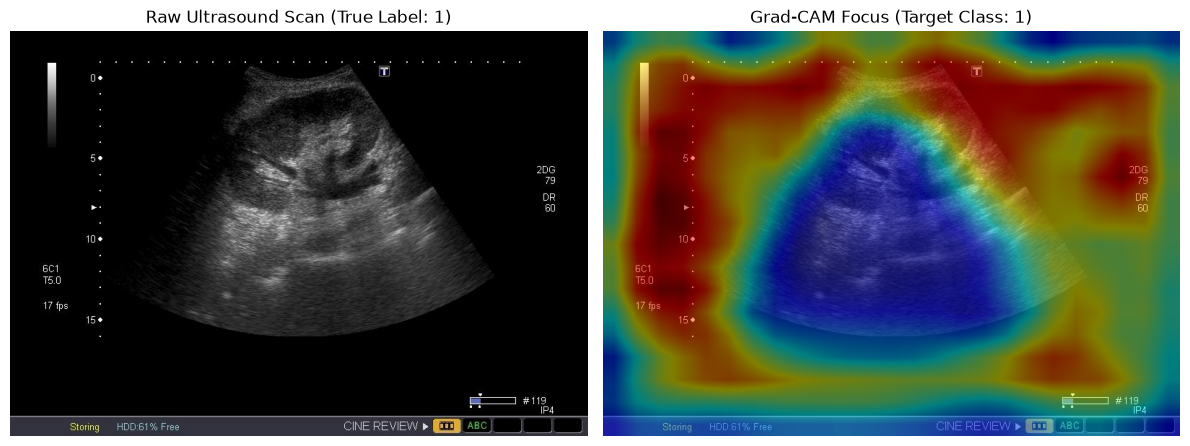

Grad-CAM saved: FULL_fold0_gradcam.png


In [36]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget


def generate_ultrasound_gradcam(
    model,
    dataset_item,
    target_class=1,
    save_path="FULL_fold0_gradcam.png"
):
    model.eval()

    device = next(model.parameters()).device
    input_tensor = dataset_item["image"].unsqueeze(0).to(device)
    true_label = dataset_item["label"].item()

    target_layers = [model.conv_head]

    cam = GradCAM(
        model=model,
        target_layers=target_layers
    )

    targets = [ClassifierOutputTarget(target_class)]

    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=targets
    )[0]

    raw_img = input_tensor.squeeze(0).cpu().numpy().transpose(1, 2, 0)
    raw_img = (
        (raw_img - raw_img.min()) /
        (raw_img.max() - raw_img.min() + 1e-8)
    )

    visualization = show_cam_on_image(
        raw_img,
        grayscale_cam,
        use_rgb=True
    )

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    axes[0].imshow(raw_img)
    axes[0].set_title(f"Raw Ultrasound Scan (True Label: {true_label})")
    axes[0].axis("off")

    axes[1].imshow(visualization)
    axes[1].set_title(f"Grad-CAM Focus (Target Class: {target_class})")
    axes[1].axis("off")

    plt.tight_layout()
    plt.savefig(save_path, dpi=300)
    plt.show()

    print("Grad-CAM saved:", save_path)


# Generate Grad-CAM for FULL fold 0
generate_ultrasound_gradcam(
    model=model,
    dataset_item=test_ds[0],
    target_class=1,
    save_path="FULL_fold0_gradcam.png"
)

In [37]:
# Get the model prediction
model.eval()

image_tensor = test_ds[0]["image"].unsqueeze(0).to(device)

with torch.no_grad():
    outputs = model(image_tensor)
    probabilities = torch.softmax(outputs, dim=1)
    predicted_class = torch.argmax(probabilities, dim=1).item()

print("True label:", test_ds[0]["label"].item())
print("Predicted class:", predicted_class)
print("Class 0 probability:", probabilities[0, 0].item())
print("Class 1 probability:", probabilities[0, 1].item())

True label: 1
Predicted class: 1
Class 0 probability: 0.0
Class 1 probability: 1.0


In [39]:
# Install pandas to create and display the Grad-CAM results table.
%pip install pandas

  Using cached pandas-3.1.0-cp314-cp314-win_amd64.whl.metadata (18 kB)
Using cached pandas-3.1.0-cp314-cp314-win_amd64.whl (10.9 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [40]:
import pandas as pd

results = pd.DataFrame([{
    "Model": "FULL",
    "Fold": 0,
    "Image": "800.jpg",
    "True_Label": 1,
    "Predicted_Class": predicted_class,
    "Class_0_Probability": probabilities[0, 0].item(),
    "Class_1_Probability": probabilities[0, 1].item(),
    "GradCAM_File": "FULL_fold0_gradcam.png"
}])

display(results)

,Model,Fold,Image,True_Label,Predicted_Class,Class_0_Probability,Class_1_Probability,GradCAM_File
0,FULL,0,800.jpg,1,1,0.0,1.0,FULL_fold0_gradcam.png


1. First Grad-CAM Experiment: FULL Model – Fold 0

Objective [BASED ON SILVIA'S PROJECT]

The objective of this first experiment is to apply Grad-CAM (Gradient-weighted Class Activation Mapping) to a trained kidney ultrasound classification model.

Grad-CAM is a visual explainability technique that helps us understand which regions of an input image contribute most to a model's prediction. It generates a heatmap that is overlaid on the original image.

    Step 1. Loading the trained model [SAME AS SILVIA'S MODEL ARCHITECTURE AND TRAINED CHECKPOINT]

        First, we loaded the previously trained EfficientNet-B0 FULL model, using the checkpoint best_efficientnet_full_fold0.pth.

        The model was reconstructed with the same architecture and its trained weights were loaded. This allows us to use the already trained model without training it again.

    Step 2. Preparing the test image [SAME AS SILVIA'S DATASET SPLIT AND PREPROCESSING PIPELINE]

        We used the test dataset created with the same preprocessing steps as the original training pipeline.

        For this first experiment, we selected the first image in the test dataset:

        Image: 800.jpg

        True label: 1

        The image was converted into a tensor, resized and normalized according to the preprocessing pipeline used for the model.

    Step 3. Generating the Grad-CAM heatmap [SAME GRAD-CAM METHOD AND TARGET LAYER AS SILVIA'S EXAMPLE]

        We applied Grad-CAM to the last convolutional feature layer of EfficientNet-B0 (model.conv_head).

        The target class was set to class 1, meaning that we generated a heatmap showing the regions that contributed to the model's output for this class.

        The resulting heatmap was overlaid on the original ultrasound image to visualize the model's activation patterns.

        [SILVIA'S EXAMPLE USED TARGET CLASS 0, WHILE WE USED TARGET CLASS 1]
        
    Step 4. Checking the model prediction

        We also checked the model's prediction for the selected image.

        The results were:

        Metric

        Result

        True label: 1

        Predicted class: 1

        Class 0 probability: 0.00

        Class 1 probability: 1.00

        The model correctly predicted the label of this particular image.

Initial observations

The Grad-CAM visualization shows different activation levels across the ultrasound image:

Red and yellow areas represent regions with higher activation for the target class.

Blue areas represent regions with lower activation.

In this first example, the strongest activations appear mainly around the outer areas of the image, while much of the central ultrasound region shows lower activation.

This observation is important because it raises the question of whether the model is focusing on relevant kidney structures or on other image features.

Conclusion

The first Grad-CAM visualization was successfully generated using the FULL model, fold 0, and one test image.

This is an initial experiment, so no general conclusions can be drawn from a single image. Further visualizations will be needed to evaluate the model's behavior across different ultrasound images and to compare the FULL and KIDNEY-FOCUSED models


## PART 3: FULL Model – 5-Fold Consensus Grad-CAM

### Objective

The objective of this experiment is to generate a consensus Grad-CAM heatmap by combining the explanations produced by the five FULL models trained using 5-fold cross-validation.

The same ultrasound image will be passed through each of the five trained models. Their individual Grad-CAM heatmaps will be normalized and averaged pixel-by-pixel to obtain a consensus visualization.

This approach aims to identify the image regions that the different fold models consistently focus on when predicting the target class.

In [46]:
# Find all FULL model checkpoints in the project's model directory.
full_model_dir = PROJECT_ROOT / "efficientnet_models"

full_checkpoints = sorted(
    glob.glob(str(full_model_dir / "best_efficientnet_full_fold*.pth"))
)

print("FULL checkpoints found:", len(full_checkpoints))

for checkpoint_path in full_checkpoints:
    print(os.path.basename(checkpoint_path))

FULL checkpoints found: 5
best_efficientnet_full_fold0.pth
best_efficientnet_full_fold1.pth
best_efficientnet_full_fold2.pth
best_efficientnet_full_fold3.pth
best_efficientnet_full_fold4.pth


In [47]:
# Load the five FULL models.
full_models = []

for checkpoint_path in full_checkpoints:
    model_fold = build_efficientnet_model(num_classes=2).to(device)

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    model_fold.load_state_dict(checkpoint)
    model_fold.eval()

    full_models.append(model_fold)

    print(f"Loaded successfully: {os.path.basename(checkpoint_path)}")

print("\nTotal FULL models loaded:", len(full_models))

Loaded successfully: best_efficientnet_full_fold0.pth
Loaded successfully: best_efficientnet_full_fold1.pth
Loaded successfully: best_efficientnet_full_fold2.pth
Loaded successfully: best_efficientnet_full_fold3.pth
Loaded successfully: best_efficientnet_full_fold4.pth

Total FULL models loaded: 5


In [48]:
# Generate individual Grad-CAM heatmaps for the five FULL models

full_heatmaps = []

# Use the same ultrasound image for all five models
input_tensor = test_ds[0]["image"].unsqueeze(0).to(device)

for fold, model_fold in enumerate(full_models):

    target_layers = [model_fold.conv_head]

    cam = GradCAM(
        model=model_fold,
        target_layers=target_layers
    )

    targets = [ClassifierOutputTarget(1)]

    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=targets
    )[0]

    # Normalize each heatmap to the range [0, 1]
    normalized_cam = (
        (grayscale_cam - grayscale_cam.min()) /
        (grayscale_cam.max() - grayscale_cam.min() + 1e-8)
    )

    full_heatmaps.append(normalized_cam)

    print(f"Grad-CAM generated for FULL fold {fold}")

print("\nTotal heatmaps generated:", len(full_heatmaps))

Grad-CAM generated for FULL fold 0
Grad-CAM generated for FULL fold 1
Grad-CAM generated for FULL fold 2
Grad-CAM generated for FULL fold 3
Grad-CAM generated for FULL fold 4

Total heatmaps generated: 5


In [49]:
# Compute the FULL consensus Grad-CAM heatmap

full_consensus_cam = np.mean(
    np.stack(full_heatmaps, axis=0),
    axis=0
)

print("Consensus heatmap shape:", full_consensus_cam.shape)
print("Minimum activation:", full_consensus_cam.min())
print("Maximum activation:", full_consensus_cam.max())

Consensus heatmap shape: (561, 800)
Minimum activation: 0.043151855
Maximum activation: 0.52724206


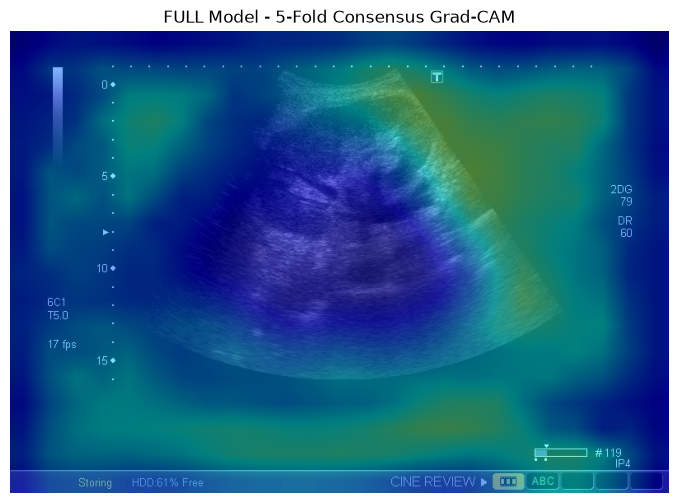

In [50]:
# Visualize the FULL consensus Grad-CAM

input_image = test_ds[0]["image"].cpu().numpy().transpose(1, 2, 0)

# Convert the normalized image back to its original intensity range
mean = np.array(mean)
std = np.array(std)

original_image = input_image * std + mean
original_image = np.clip(original_image, 0, 1)

# Create the Grad-CAM overlay
full_consensus_visualization = show_cam_on_image(
    original_image.astype(np.float32),
    full_consensus_cam,
    use_rgb=True
)

# Display and save the result
plt.figure(figsize=(12, 6))
plt.imshow(full_consensus_visualization)
plt.title("FULL Model - 5-Fold Consensus Grad-CAM")
plt.axis("off")
plt.savefig("FULL_5fold_consensus_gradcam.png", bbox_inches="tight")
plt.show()

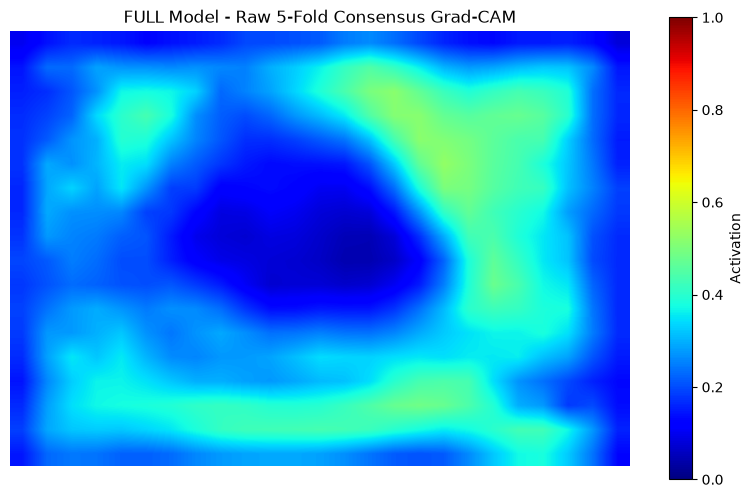

In [51]:
# Display the raw FULL consensus Grad-CAM

plt.figure(figsize=(10, 6))

plt.imshow(full_consensus_cam, cmap="jet", vmin=0, vmax=1)
plt.colorbar(label="Activation")
plt.title("FULL Model - Raw 5-Fold Consensus Grad-CAM")
plt.axis("off")

plt.show()

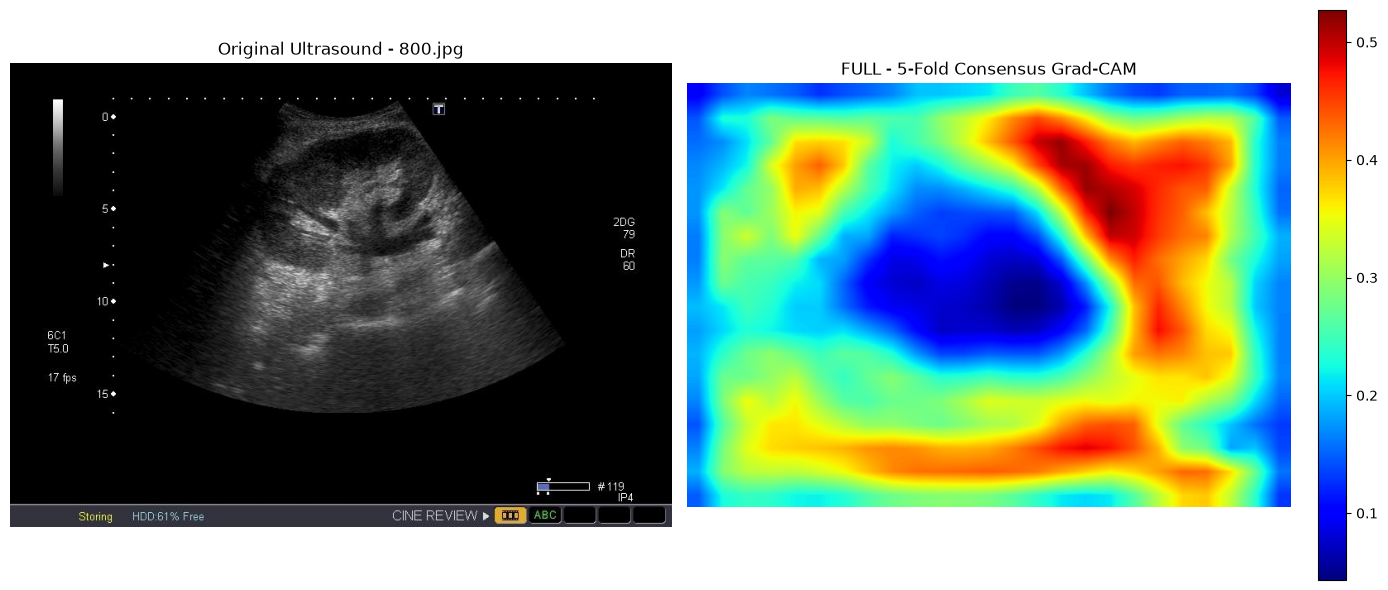

In [52]:
# Compare the original ultrasound with the consensus heatmap

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Original ultrasound image
axes[0].imshow(original_image)
axes[0].set_title("Original Ultrasound - 800.jpg")
axes[0].axis("off")

# Consensus Grad-CAM
im = axes[1].imshow(
    full_consensus_cam,
    cmap="jet",
    vmin=full_consensus_cam.min(),
    vmax=full_consensus_cam.max()
)
axes[1].set_title("FULL - 5-Fold Consensus Grad-CAM")
axes[1].axis("off")

plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

### Summary and Observations

Grad-CAM heatmaps were generated for all five FULL models using the same ultrasound image (800.jpg) and target class 1. Each heatmap was normalized to the [0, 1] range, and the five maps were averaged pixel-by-pixel to obtain the 5-fold consensus heatmap.

The consensus visualization showed a similar activation pattern to the individual fold 0 Grad-CAM, with stronger activations mainly around the peripheral regions of the image rather than its central area.

The final consensus heatmap was saved as `FULL_5fold_consensus_gradcam.png`. These results will be compared with the KIDNEY-FOCUSED models in the next experiment.

## PART 4: KIDNEY-FOCUSED Models – Grad-CAM Explainability
This section applies the same Grad-CAM explainability procedure to the five KIDNEY-FOCUSED models (folds 0–4).

For each model, we will generate a Grad-CAM heatmap, normalize it to the [0, 1] range, and then calculate the pixel-wise average across all five folds to obtain a consensus heatmap.

In [54]:
# Define the relative paths to the five KIDNEY-FOCUSED checkpoints.
KIDNEY_FOCUSED_MODEL_PATHS = {
    fold: Path("efficientnet_models") / f"best_efficientnet_kidney_focused_fold{fold}.pth"
    for fold in range(5)
}

# Verify that all checkpoint files exist in the project directory.
for fold, relative_path in KIDNEY_FOCUSED_MODEL_PATHS.items():
    checkpoint_path = PROJECT_ROOT / relative_path
    print(f"Fold {fold}: {relative_path} | Exists: {checkpoint_path.exists()}")

Fold 0: efficientnet_models\best_efficientnet_kidney_focused_fold0.pth | Exists: True
Fold 1: efficientnet_models\best_efficientnet_kidney_focused_fold1.pth | Exists: True
Fold 2: efficientnet_models\best_efficientnet_kidney_focused_fold2.pth | Exists: True
Fold 3: efficientnet_models\best_efficientnet_kidney_focused_fold3.pth | Exists: True
Fold 4: efficientnet_models\best_efficientnet_kidney_focused_fold4.pth | Exists: True


In [56]:
%pip show torch

Name: torch
Version: 2.15.0
Summary: Tensors and Dynamic neural networks in Python with strong GPU acceleration
Home-page: https://pytorch.org
Author: 
Author-email: PyTorch Team <packages@pytorch.org>
License-Expression: Apache-2.0 AND Apache-2.0 WITH LLVM-exception AND BSD-2-Clause AND BSD-3-Clause AND BSL-1.0 AND ISC AND MIT AND Zlib
Location: c:\Users\Usuario\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages
Requires: filelock, fsspec, jinja2, networkx, setuptools, sympy, typing-extensions
Required-by: grad-cam, timm, torchvision
Note: you may need to restart the kernel to use updated packages.


In [57]:
%pip install torch torchvision

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch: 2.15.0+cpu
CUDA available: False


In [58]:
%pip install grad-cam

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [59]:
import pytorch_grad_cam

print("Grad-CAM: correctly installed")

Grad-CAM: correctly installed


In [60]:
import os

# Define the directory containing the five KIDNEY-FOCUSED model checkpoints.
KIDNEY_FOCUSED_MODEL_DIR = (
    r"C:\Users\Usuario\Documents\UNI 4\PROYECTO EN CD"
    r"\Project-data-science\efficientnet_models"
)

# Create a dictionary with the checkpoint path for each cross-validation fold (0–4).
KIDNEY_FOCUSED_MODEL_PATHS = {
    fold: os.path.join(
        KIDNEY_FOCUSED_MODEL_DIR,
        f"best_efficientnet_kidney_focused_fold{fold}.pth"
    )
    for fold in range(5)
}

# Check that all five model checkpoint files exist before loading them.
for fold, path in KIDNEY_FOCUSED_MODEL_PATHS.items():
    print(f"Fold {fold}: {os.path.exists(path)}")

Fold 0: True
Fold 1: True
Fold 2: True
Fold 3: True
Fold 4: True


In [61]:
# Import glob to search for model checkpoint files using filename patterns.
import glob

In [62]:
# Find all KIDNEY-FOCUSED model checkpoints
kidney_focused_checkpoints = sorted(
    glob.glob(os.path.join(KIDNEY_FOCUSED_MODEL_DIR, "best_efficientnet_kidney_focused_fold*.pth"))
)

print("KIDNEY-FOCUSED checkpoints found:", len(kidney_focused_checkpoints))

for checkpoint in kidney_focused_checkpoints:
    print(os.path.basename(checkpoint))


# Load the five KIDNEY-FOCUSED models
kidney_focused_models = []

for checkpoint_path in kidney_focused_checkpoints:
    model_fold = build_efficientnet_model(num_classes=2).to(device)

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    model_fold.load_state_dict(checkpoint)
    model_fold.eval()

    kidney_focused_models.append(model_fold)

    print(f"Loaded successfully: {os.path.basename(checkpoint_path)}")

print("\nTotal KIDNEY-FOCUSED models loaded:", len(kidney_focused_models))

KIDNEY-FOCUSED checkpoints found: 5
best_efficientnet_kidney_focused_fold0.pth
best_efficientnet_kidney_focused_fold1.pth
best_efficientnet_kidney_focused_fold2.pth
best_efficientnet_kidney_focused_fold3.pth
best_efficientnet_kidney_focused_fold4.pth
Loaded successfully: best_efficientnet_kidney_focused_fold0.pth
Loaded successfully: best_efficientnet_kidney_focused_fold1.pth
Loaded successfully: best_efficientnet_kidney_focused_fold2.pth
Loaded successfully: best_efficientnet_kidney_focused_fold3.pth
Loaded successfully: best_efficientnet_kidney_focused_fold4.pth

Total KIDNEY-FOCUSED models loaded: 5


In [63]:
# Generate Grad-CAM heatmaps for the five KIDNEY-FOCUSED models.

# Initialize an empty list to store the normalized heatmaps.
kidney_focused_heatmaps = []

# Use the same ultrasound image for all five models.
input_tensor = test_ds[0]["image"].unsqueeze(0).to(device)

for fold, model_fold in enumerate(kidney_focused_models):

    # Select the final convolutional layer for Grad-CAM.
    target_layers = [model_fold.conv_head]

    # Initialize Grad-CAM for the current model.
    cam = GradCAM(
        model=model_fold,
        target_layers=target_layers
    )

    # Generate the heatmap for class 1.
    targets = [ClassifierOutputTarget(1)]

    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=targets
    )[0]

    # Normalize the heatmap to the range [0, 1].
    normalized_cam = (
        (grayscale_cam - grayscale_cam.min()) /
        (grayscale_cam.max() - grayscale_cam.min() + 1e-8)
    )

    # Store the normalized heatmap.
    kidney_focused_heatmaps.append(normalized_cam)

    print(f"Grad-CAM generated for KIDNEY-FOCUSED fold {fold}")

print("\nTotal heatmaps generated:", len(kidney_focused_heatmaps))

Grad-CAM generated for KIDNEY-FOCUSED fold 0
Grad-CAM generated for KIDNEY-FOCUSED fold 1
Grad-CAM generated for KIDNEY-FOCUSED fold 2
Grad-CAM generated for KIDNEY-FOCUSED fold 3
Grad-CAM generated for KIDNEY-FOCUSED fold 4

Total heatmaps generated: 5


In [64]:
# Compute the KIDNEY-FOCUSED consensus Grad-CAM heatmap.
# The consensus map is obtained by averaging the five normalized heatmaps pixel-wise.

kidney_focused_consensus_cam = np.mean(
    np.stack(kidney_focused_heatmaps, axis=0),
    axis=0
)

# Display the shape and activation range of the consensus heatmap.
print("Consensus heatmap shape:", kidney_focused_consensus_cam.shape)
print("Minimum activation:", kidney_focused_consensus_cam.min())
print("Maximum activation:", kidney_focused_consensus_cam.max())

Consensus heatmap shape: (561, 800)
Minimum activation: 0.0998951
Maximum activation: 0.7605826


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.58606..5.204839].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.58606..5.204839].


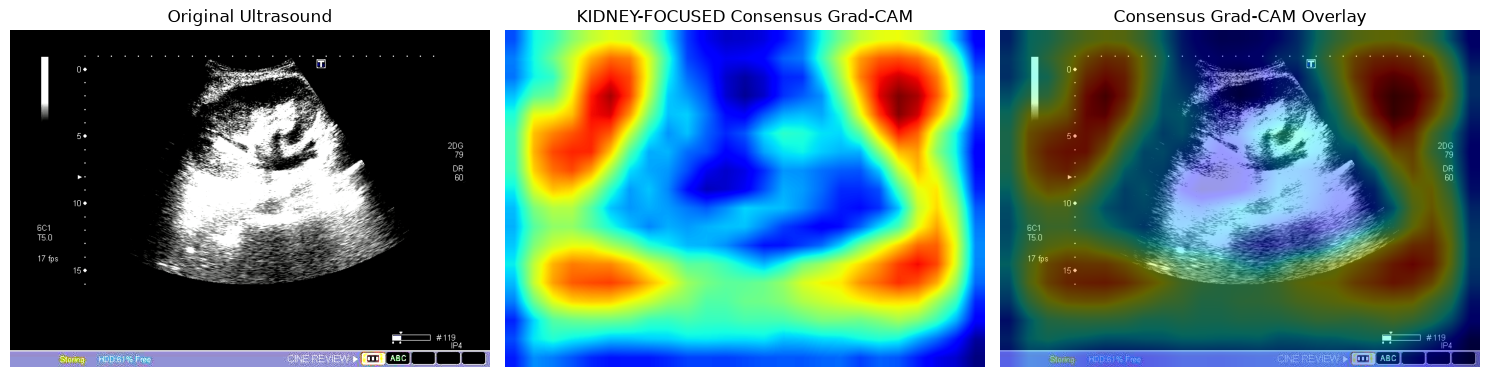

In [65]:
import matplotlib.pyplot as plt

# Retrieve the original ultrasound image used to generate the heatmaps.
original_image = test_ds[0]["image"].permute(1, 2, 0).cpu().numpy()

# Normalize the consensus heatmap for visualization.
consensus_cam = (
    (kidney_focused_consensus_cam - kidney_focused_consensus_cam.min()) /
    (kidney_focused_consensus_cam.max() - kidney_focused_consensus_cam.min() + 1e-8)
)

# Display the original image and the KIDNEY-FOCUSED consensus heatmap.
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title("Original Ultrasound")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(consensus_cam, cmap="jet")
plt.title("KIDNEY-FOCUSED Consensus Grad-CAM")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(original_image)
plt.imshow(consensus_cam, cmap="jet", alpha=0.4)
plt.title("Consensus Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

### Explanation 4.KIDNEY-FOCUSED Models – Consensus Grad-CAM

The five KIDNEY-FOCUSED EfficientNet-B0 models were loaded and used to generate individual Grad-CAM heatmaps for the same ultrasound image.

Each heatmap was normalized to [0, 1], and the five maps were averaged pixel-wise to obtain a consensus heatmap.

Finally, the consensus was visualized both independently and overlaid on the original ultrasound image.

This provides a combined explanation of the regions highlighted by the five cross-validation models.

## Part 5 – FULL vs KIDNEY-FOCUSED Consensus Comparison

This section compares the FULL and KIDNEY-FOCUSED consensus Grad-CAM heatmaps using the same ultrasound image to identify similarities and differences in their highlighted regions.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.58606..5.204839].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.58606..5.204839].


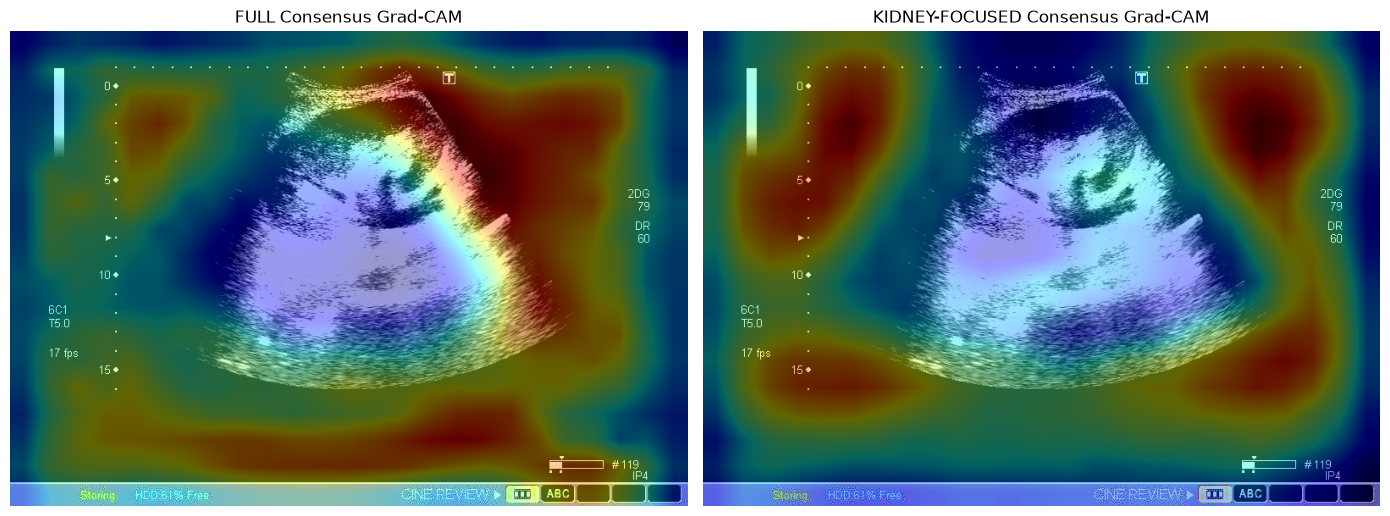

In [66]:
# Compare FULL and KIDNEY-FOCUSED consensus Grad-CAM overlays.

# Retrieve the original ultrasound image.
original_image = test_ds[0]["image"].permute(1, 2, 0).cpu().numpy()

# Normalize both consensus heatmaps to the [0, 1] range.
full_cam = (
    (full_consensus_cam - full_consensus_cam.min()) /
    (full_consensus_cam.max() - full_consensus_cam.min() + 1e-8)
)

kidney_cam = (
    (kidney_focused_consensus_cam - kidney_focused_consensus_cam.min()) /
    (kidney_focused_consensus_cam.max() - kidney_focused_consensus_cam.min() + 1e-8)
)

# Display both overlays using the same ultrasound image.
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.imshow(full_cam, cmap="jet", alpha=0.4)
plt.title("FULL Consensus Grad-CAM")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(original_image)
plt.imshow(kidney_cam, cmap="jet", alpha=0.4)
plt.title("KIDNEY-FOCUSED Consensus Grad-CAM")
plt.axis("off")

plt.tight_layout()
plt.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.58606..5.204839].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.58606..5.204839].


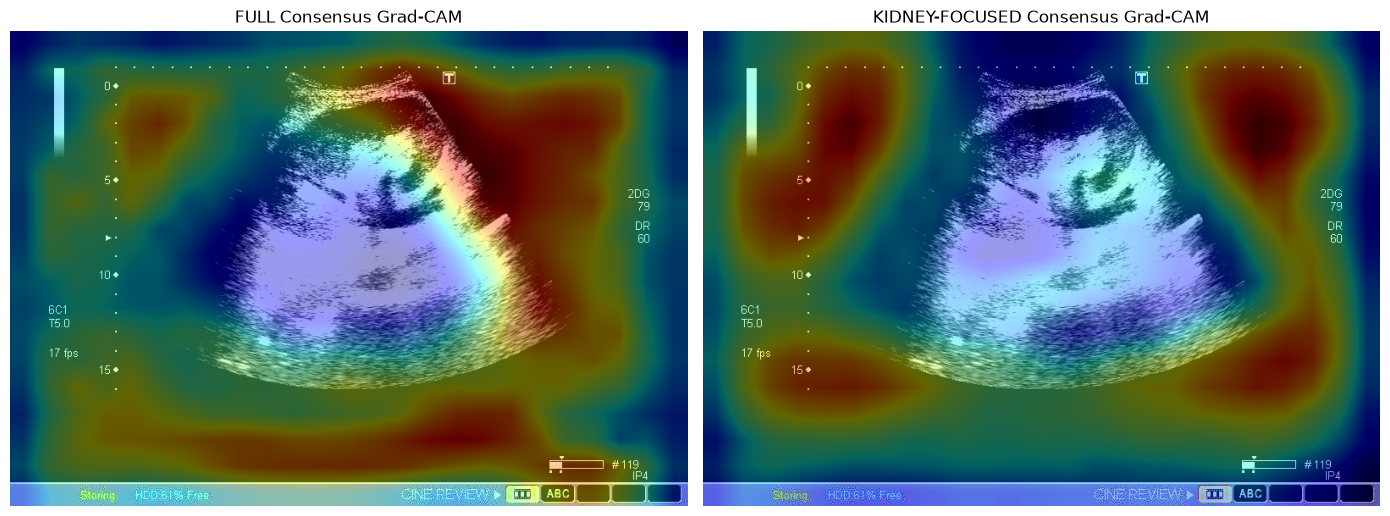

Comparison saved to: c:\Users\Usuario\Documents\UNI 4\PROYECTO EN CD\Project-data-science\gradcam_results\FULL_vs_KIDNEY_FOCUSED_consensus.png


In [67]:
# Save the comparison between FULL and KIDNEY-FOCUSED consensus Grad-CAM overlays.

output_dir = PROJECT_ROOT / "gradcam_results"
output_dir.mkdir(parents=True, exist_ok=True)

comparison_path = output_dir / "FULL_vs_KIDNEY_FOCUSED_consensus.png"

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.imshow(full_cam, cmap="jet", alpha=0.4)
plt.title("FULL Consensus Grad-CAM")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(original_image)
plt.imshow(kidney_cam, cmap="jet", alpha=0.4)
plt.title("KIDNEY-FOCUSED Consensus Grad-CAM")
plt.axis("off")

plt.tight_layout()
plt.savefig(comparison_path, dpi=300, bbox_inches="tight")
plt.show()

print("Comparison saved to:", comparison_path)

## Part 6 – Interpretation of Grad-CAM Results

The FULL and KIDNEY-FOCUSED consensus Grad-CAM maps show similar activation patterns. In both models, the strongest activations appear mainly towards the outer regions of the ultrasound image, rather than being clearly concentrated in the kidney region.

Despite being trained with kidney-focused images, the KIDNEY-FOCUSED model does not appear to shift its attention substantially towards the kidney when compared with the FULL model.

It is important to note that Grad-CAM highlights image regions that contribute to the model's predictions, but does not necessarily identify specific anatomical structures.

### Overall Conclusion

Based on the Grad-CAM analysis, the KIDNEY-FOCUSED model does not show a clear improvement in attention localization compared with the FULL model.

Therefore, focusing the input images on the kidney does not appear to have substantially changed the visual attention patterns learned by the model.

However, this analysis alone is not sufficient to determine which model performs better overall. Classification metrics must also be considered to assess their predictive performance.

### Further Investigation – Individual Grad-CAM Analysis

The initial consensus Grad-CAM visualizations showed weak activation patterns, with no clear concentration of attention on the kidney region. To investigate this further, the individual Grad-CAM maps of all ten models (five FULL and five KIDNEY-FOCUSED) were examined separately.

This additional analysis aims to determine whether the observed activation patterns are consistent across the different folds or whether some models show different attention behaviours.

Particular attention is given to identifying whether the models focus on the kidney region or mainly on peripheral areas of the ultrasound images.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.58606..5.204839].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.58606..5.204839].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.58606..5.204839].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.58606..5.204839].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.58606..5.204839].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.58606..5.204839].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.58606..5.204839].
Clippi

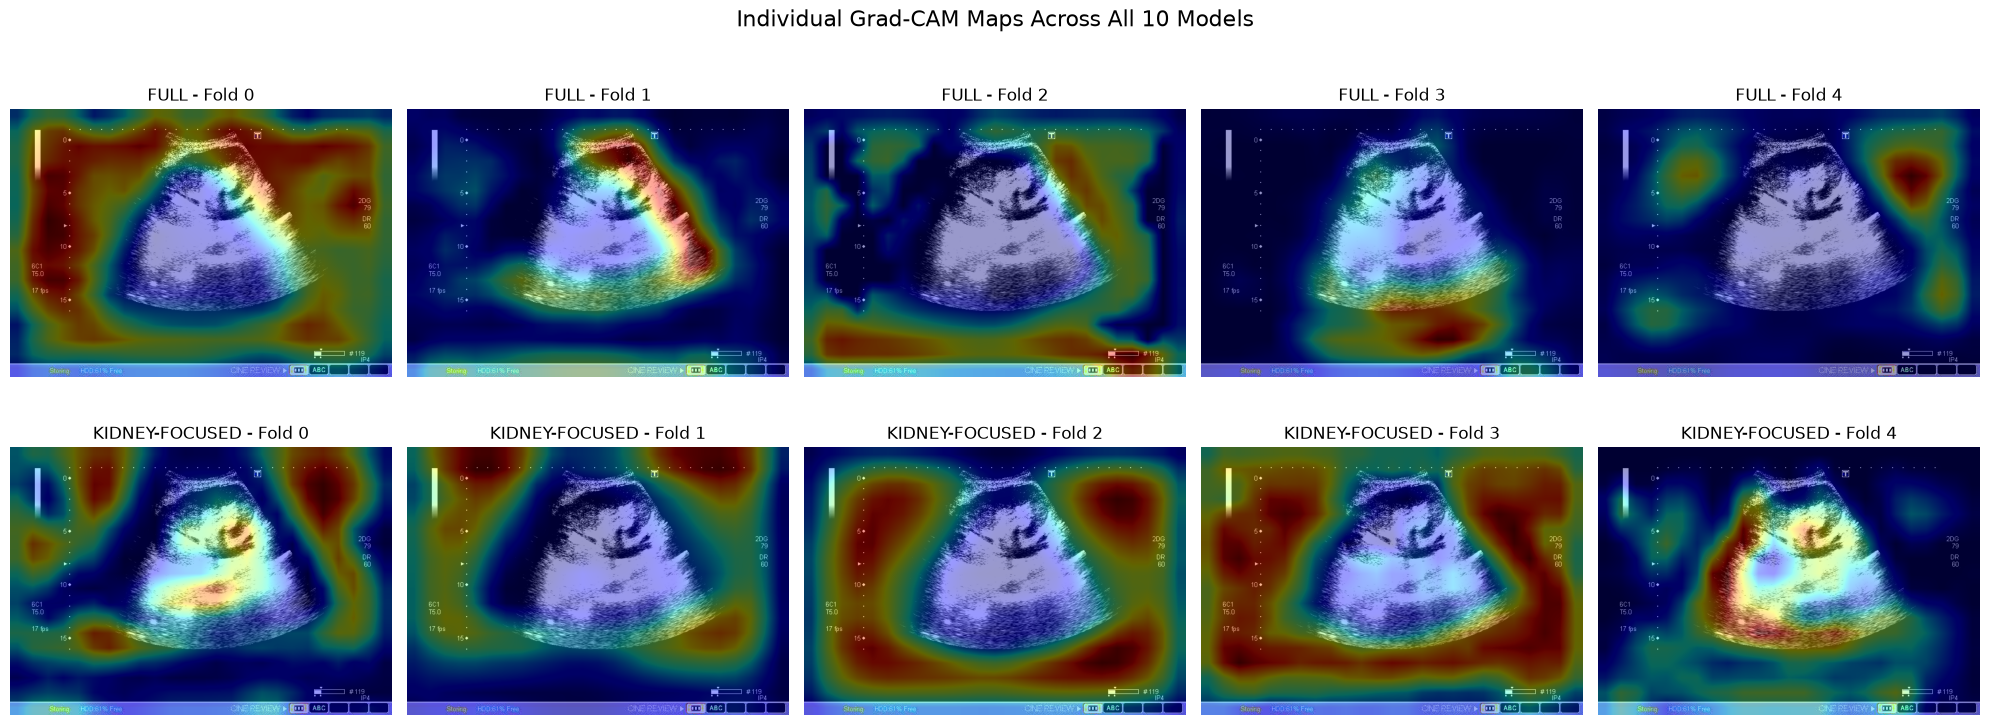

In [68]:

# Visualize the individual Grad-CAM heatmaps for all 10 models.

fig, axes = plt.subplots(2, 5, figsize=(20, 8))

# Display the five FULL model heatmaps.
for fold in range(5):
    axes[0, fold].imshow(original_image)
    axes[0, fold].imshow(full_heatmaps[fold], cmap="jet", alpha=0.4)
    axes[0, fold].set_title(f"FULL - Fold {fold}")
    axes[0, fold].axis("off")

# Display the five KIDNEY-FOCUSED model heatmaps.
for fold in range(5):
    axes[1, fold].imshow(original_image)
    axes[1, fold].imshow(kidney_focused_heatmaps[fold], cmap="jet", alpha=0.4)
    axes[1, fold].set_title(f"KIDNEY-FOCUSED - Fold {fold}")
    axes[1, fold].axis("off")

plt.suptitle("Individual Grad-CAM Maps Across All 10 Models", fontsize=16)
plt.tight_layout()
plt.show()


### Observations from Individual Grad-CAM Maps

Most models show weak activation patterns, with predominantly blue heatmaps. FULL Fold 1 and KIDNEY-FOCUSED Fold 4 show some stronger activation over the kidney region, while KIDNEY-FOCUSED Folds 2 and 3 mainly highlight peripheral areas.

This indicates variability in the regions highlighted by the different models, with no consistent focus on the kidney across all folds.